<a href="https://colab.research.google.com/github/saichandanss2190/ITA0315-Mobile-Computing/blob/main/MC_Exp_18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Blocking probability (%)
E \ m         5       10       15       20       25       30
    2     3.670    0.004    0.000    0.000    0.000    0.000
    5    28.487    1.838    0.016    0.000    0.000    0.000
   10    56.395   21.458    3.650    0.187    0.003    0.000
   20    76.436   53.796   33.000   15.889    5.022    0.846

For E = 10 Erlangs and GoS = 2% -> channels required = 17


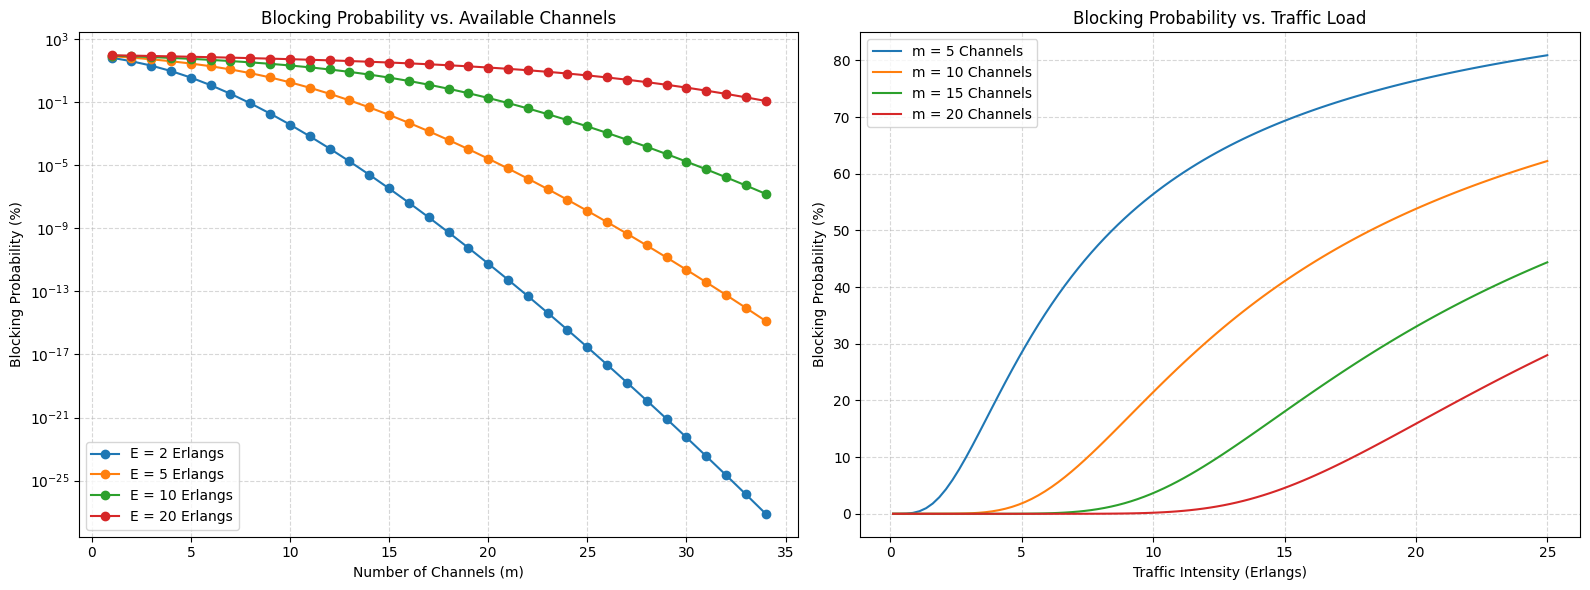

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def erlang_b(E, m):
    """Blocking probability using the recursive Erlang-B formula."""
    B = 1.0
    for k in range(1, m + 1):
        B = (E * B) / (k + E * B)
    return B

# Input values
loads = [2, 5, 10, 20]
channels = [5, 10, 15, 20, 25, 30]

# Print Table Output
print("Blocking probability (%)")
print("E \\ m " + "".join(f"{m:>9}" for m in channels))
for E in loads:
    print(f"{E:>5} " + "".join(f"{100*erlang_b(E, m):9.3f}" for m in channels))

E_target, target_prob = 10, 0.02
m_req = 1
while erlang_b(E_target, m_req) > target_prob:
    m_req += 1
print(f"\nFor E = {E_target} Erlangs and GoS = {target_prob*100:.0f}% -> channels required = {m_req}")

# --- Plotting ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Graph 1: Blocking Probability vs. Number of Channels for various loads
channel_range = np.arange(1, 35)
for E in loads:
    probs = [erlang_b(E, int(m)) * 100 for m in channel_range]
    ax1.plot(channel_range, probs, marker='o', label=f'E = {E} Erlangs')
ax1.set_title('Blocking Probability vs. Available Channels')
ax1.set_xlabel('Number of Channels (m)')
ax1.set_ylabel('Blocking Probability (%)')
ax1.set_yscale('log') # Log scale helps view small percentages
ax1.grid(True, which="both", linestyle='--', alpha=0.5)
ax1.legend()

# Graph 2: Blocking Probability vs. Traffic Load for various channels
load_range = np.linspace(0.1, 25, 100)
for m in [5, 10, 15, 20]:
    probs = [erlang_b(E, m) * 100 for E in load_range]
    ax2.plot(load_range, probs, label=f'm = {m} Channels')
ax2.set_title('Blocking Probability vs. Traffic Load')
ax2.set_xlabel('Traffic Intensity (Erlangs)')
ax2.set_ylabel('Blocking Probability (%)')
ax2.grid(True, which="both", linestyle='--', alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()